# Digital Image Processing Lab
## Experiment: Spatial Filtering — Blur, Prewitt and Sobel

Spatial filtering modifies a pixel using its neighborhood. A kernel determines how neighboring pixels contribute. **Correlation** uses the kernel as given; **convolution** first rotates the kernel by 180°. fileciteturn7file1L94-L106 fileciteturn7file1L154-L158

**Objectives:** Implement correlation and convolution manually, apply a box blur, implement Prewitt and Sobel edge detection, visualize Sobel edges, and create a sharpened image.

## 1. Load a Grayscale Image

Saving Screenshot 2026-03-26 at 10.33.21 PM.png to Screenshot 2026-03-26 at 10.33.21 PM.png


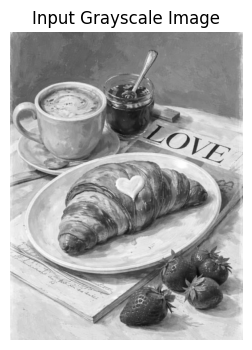

Image shape: (1402, 1060)


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

image = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(6,4))
plt.imshow(image, cmap="gray")
plt.title("Input Grayscale Image")
plt.axis("off")
plt.show()

print("Image shape:", image.shape)

## 2. Correlation
The kernel is used without flipping.

In [ ]:
def correlation(image, kernel):
    h, w = image.shape
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2

    padded = np.pad(image, ((ph, ph), (pw, pw)), mode="edge")
    output = np.zeros_like(image, dtype=np.float32)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]
            output[i,j] = np.sum(region * kernel)

    return output

## 3. Convolution
Convolution uses the same operation after rotating the kernel by 180°.

In [ ]:
def convolution(image, kernel):
    flipped = np.flip(kernel)
    return correlation(image, flipped)

## 4. Box Blur / Average Filter

A box blur gives equal weight to all pixels in the neighborhood and smooths rapid intensity variations. fileciteturn7file1L170-L180

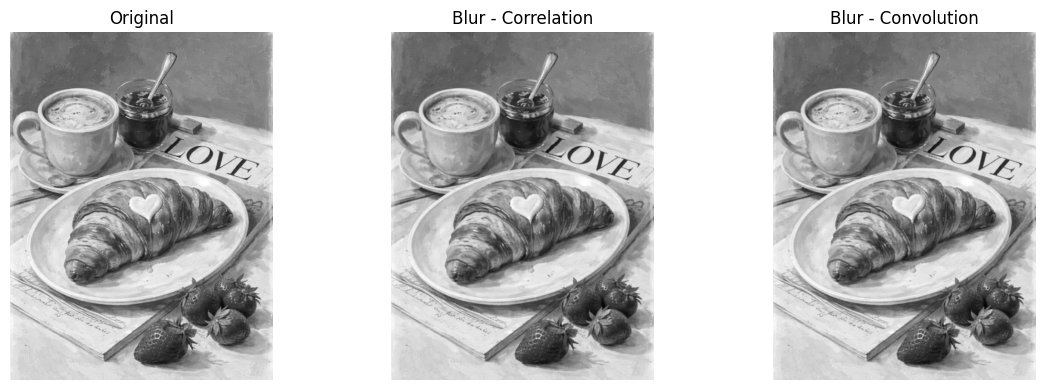

In [ ]:
box_kernel = np.ones((3,3), dtype=np.float32) / 9

blur_corr = np.clip(correlation(image, box_kernel), 0, 255).astype(np.uint8)
blur_conv = np.clip(convolution(image, box_kernel), 0, 255).astype(np.uint8)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(image, cmap="gray")
plt.title("Original")
plt.axis("off")
plt.subplot(1,3,2)
plt.imshow(blur_corr, cmap="gray")
plt.title("Blur - Correlation")
plt.axis("off")
plt.subplot(1,3,3)
plt.imshow(blur_conv, cmap="gray")
plt.title("Blur - Convolution")
plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Prewitt Filter

Prewitt approximates first-order derivatives and detects rapid intensity transitions. fileciteturn7file1L193-L207

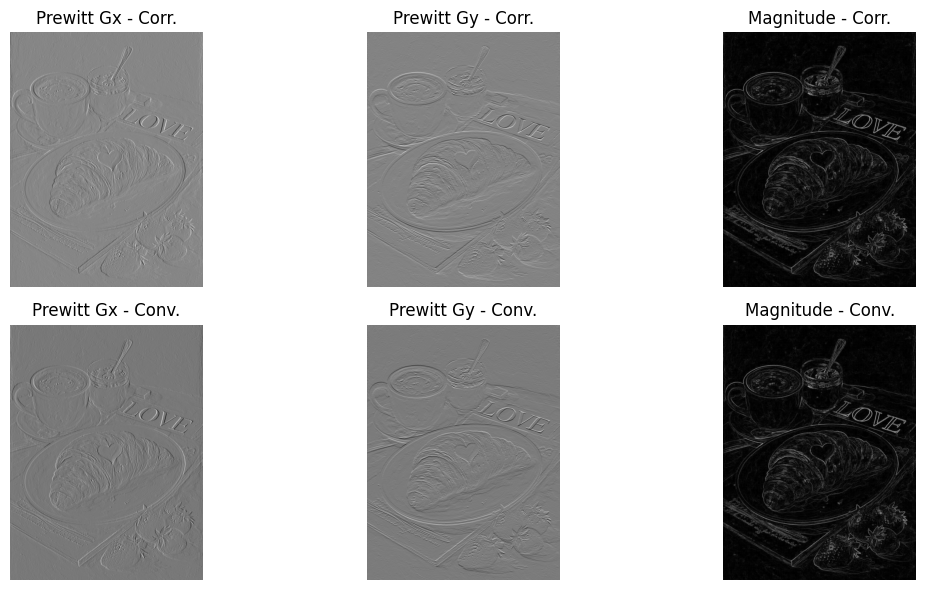

In [ ]:
prewitt_x = np.array([
    [-1,0,1],
    [-1,0,1],
    [-1,0,1]
], dtype=np.float32)

prewitt_y = np.array([
    [-1,-1,-1],
    [0,0,0],
    [1,1,1]
], dtype=np.float32)

px_corr = correlation(image, prewitt_x)
py_corr = correlation(image, prewitt_y)
px_conv = convolution(image, prewitt_x)
py_conv = convolution(image, prewitt_y)

plt.figure(figsize=(12,6))
plt.subplot(2,3,1); plt.imshow(px_corr,cmap="gray"); plt.title("Prewitt Gx - Corr."); plt.axis("off")
plt.subplot(2,3,2); plt.imshow(py_corr,cmap="gray"); plt.title("Prewitt Gy - Corr."); plt.axis("off")
plt.subplot(2,3,3); plt.imshow(np.hypot(px_corr,py_corr),cmap="gray"); plt.title("Magnitude - Corr."); plt.axis("off")
plt.subplot(2,3,4); plt.imshow(px_conv,cmap="gray"); plt.title("Prewitt Gx - Conv."); plt.axis("off")
plt.subplot(2,3,5); plt.imshow(py_conv,cmap="gray"); plt.title("Prewitt Gy - Conv."); plt.axis("off")
plt.subplot(2,3,6); plt.imshow(np.hypot(px_conv,py_conv),cmap="gray"); plt.title("Magnitude - Conv."); plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Sobel Filter

Sobel is also a first-order derivative operator. Its central row/column has greater weight because of the ±2 coefficients. fileciteturn7file1L223-L240

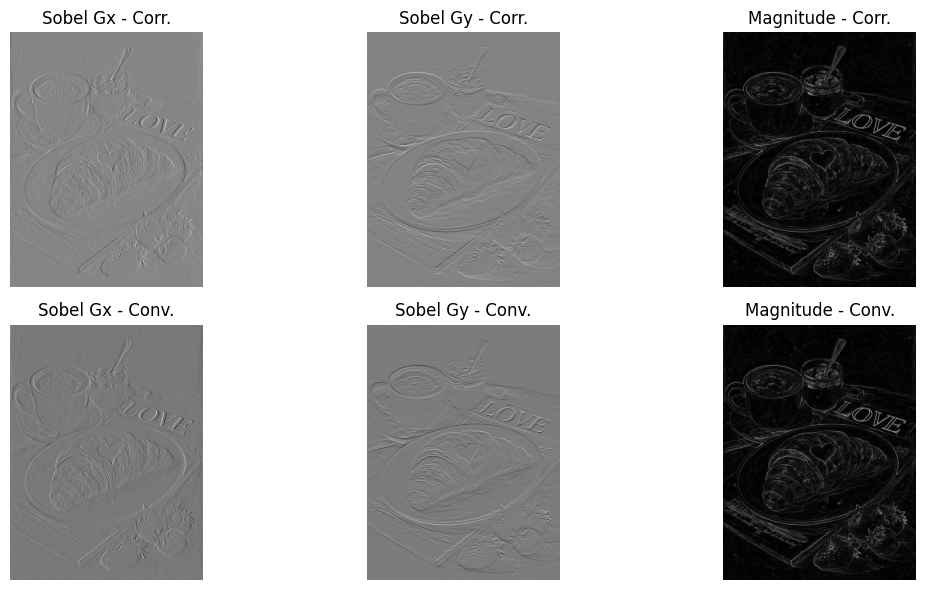

In [ ]:
sobel_x = np.array([
    [-1,0,1],
    [-2,0,2],
    [-1,0,1]
], dtype=np.float32)

sobel_y = np.array([
    [-1,-2,-1],
    [0,0,0],
    [1,2,1]
], dtype=np.float32)

sx_corr = correlation(image, sobel_x)
sy_corr = correlation(image, sobel_y)
sx_conv = convolution(image, sobel_x)
sy_conv = convolution(image, sobel_y)

plt.figure(figsize=(12,6))
plt.subplot(2,3,1); plt.imshow(sx_corr,cmap="gray"); plt.title("Sobel Gx - Corr."); plt.axis("off")
plt.subplot(2,3,2); plt.imshow(sy_corr,cmap="gray"); plt.title("Sobel Gy - Corr."); plt.axis("off")
plt.subplot(2,3,3); plt.imshow(np.hypot(sx_corr,sy_corr),cmap="gray"); plt.title("Magnitude - Corr."); plt.axis("off")
plt.subplot(2,3,4); plt.imshow(sx_conv,cmap="gray"); plt.title("Sobel Gx - Conv."); plt.axis("off")
plt.subplot(2,3,5); plt.imshow(sy_conv,cmap="gray"); plt.title("Sobel Gy - Conv."); plt.axis("off")
plt.subplot(2,3,6); plt.imshow(np.hypot(sx_conv,sy_conv),cmap="gray"); plt.title("Magnitude - Conv."); plt.axis("off")
plt.tight_layout()
plt.show()

## 7. Sobel Edge Detection

The gradient magnitude is:

\[
M=\sqrt{G_x^2+G_y^2}
\]

A large magnitude indicates a strong intensity transition. fileciteturn7file1L245-L262

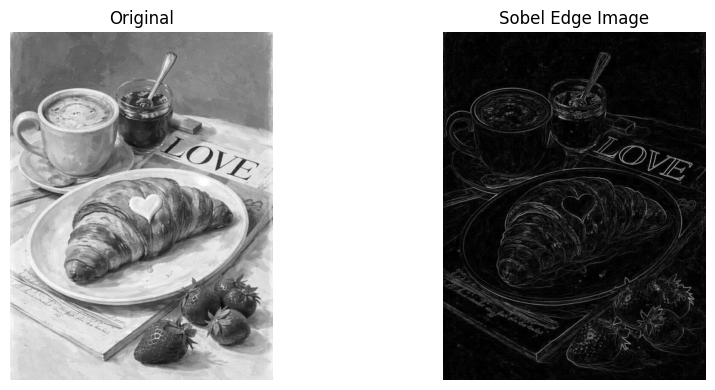

In [ ]:
magnitude = np.hypot(sx_corr, sy_corr)

edges = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(image,cmap="gray")
plt.title("Original")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(edges,cmap="gray")
plt.title("Sobel Edge Image")
plt.axis("off")
plt.tight_layout()
plt.show()

## 8. Sharpening Using Gradient Magnitude

Gradient magnitude from the Prewitt and Sobel edge detectors can be used to emphasize edges and fine details. The gradient magnitude is first normalized to the 0–255 range, then added to the original image with a sharpening strength `alpha`.


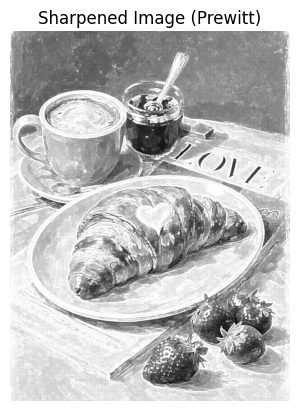

In [ ]:
# Sharpening using Prewitt gradient magnitude
alpha = 2  # sharpening strength

# Calculate total Prewitt gradient magnitude
total_gradient_prewitt = np.hypot(px_corr, py_corr)

# Ensure float for calculation
img_float = image.astype(np.float32)

# Normalize gradient magnitude
grad_norm = (total_gradient_prewitt / total_gradient_prewitt.max()) * 255

# Sharpening
sharpen_img_prewitt = img_float + alpha * grad_norm

# Clip and convert back
sharpen_img_prewitt = np.clip(sharpen_img_prewitt, 0, 255).astype(np.uint8)

# Display
plt.imshow(sharpen_img_prewitt, cmap='gray')
plt.title('Sharpened Image (Prewitt)')
plt.axis('off')
plt.show()


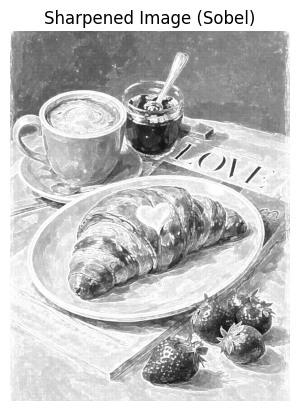

In [ ]:
# Sharpening using Sobel gradient magnitude
alpha = 2  # sharpening strength

# Calculate total Sobel gradient magnitude
total_gradient_sobel = np.hypot(sx_corr, sy_corr)

# Ensure float for calculation
img_float = image.astype(np.float32)

# Normalize gradient magnitude
grad_norm = (total_gradient_sobel / total_gradient_sobel.max()) * 255

# Sharpening
sharpen_img_sobel = img_float + alpha * grad_norm

# Clip and convert back
sharpen_img_sobel = np.clip(sharpen_img_sobel, 0, 255).astype(np.uint8)

# Display
plt.imshow(sharpen_img_sobel, cmap='gray')
plt.title('Sharpened Image (Sobel)')
plt.axis('off')
plt.show()


## Lab Observation

1. Compare blur using correlation and convolution.
2. Why do they give the same result for the symmetric box kernel?
3. Compare Prewitt and Sobel.
4. Which image regions are highlighted by Sobel?
5. How does sharpening change the appearance of the image?